In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [21]:
# Connect and Access Git Repository

import sys
from getpass import getpass
from pathlib import Path

GITHUB_USERNAME = "sharaffatima"
REPO_NAME = "bachelor-thesis"



token = getpass("GitHub token: ")


REPO_URL = f"https://{token}@github.com/{GITHUB_USERNAME}/{REPO_NAME}.git"
REPO_DIR = Path("/content") / REPO_NAME


if not REPO_DIR.exists():
    !git clone {REPO_URL} {REPO_DIR}
else:
    %cd {REPO_DIR}
    !git pull

%cd {REPO_DIR}
sys.path.append(str(REPO_DIR))

print("Repo exists:", REPO_DIR.exists())

GitHub token: ··········
/content/bachelor-thesis
remote: Enumerating objects: 7, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 4 (delta 3), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (4/4), 947.69 KiB | 1.54 MiB/s, done.
From https://github.com/sharaffatima/bachelor-thesis
   0142431..c697dbd  main       -> origin/main
Updating 0142431..c697dbd
Fast-forward
 notebooks/03_train_tranad.ipynb | 266 +++++++++++++++++++++-------------------
 1 file changed, 143 insertions(+), 123 deletions(-)
/content/bachelor-thesis
Repo exists: True


In [22]:
# Imports
import os
import numpy as np
import torch
from torch.utils.data import DataLoader


# global configuration

REPO_DIR = Path("/content/bachelor-thesis")
sys.path.append(str(REPO_DIR))

from utils.dataset import PTBXLTranADDataset
from explainability.attention import TranADExplainability
from utils.seed import set_seed, RANDOM_SEED
from models.tranad import TranADMainModel

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_seed(RANDOM_SEED)
print(f"Active device: {DEVICE}")

Active device: cuda


In [23]:
DATA_DIR = Path("/content/drive/MyDrive/ECG data")
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = DATA_DIR / "results"

MODEL_DIR = RESULTS_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

TRANAD_MODEL_PATH = MODEL_DIR / "tranad_15epochs.pt"
TRANAD_RESULTS_PATH = RESULTS_DIR / "tranad_15epochs_results.npz"

print("MODEL_DIR:", MODEL_DIR)
print("TRANAD_MODEL_PATH:", TRANAD_MODEL_PATH)
print("TRANAD_RESULTS_PATH:", TRANAD_RESULTS_PATH)

MODEL_DIR: /content/drive/MyDrive/ECG data/results/models
TRANAD_MODEL_PATH: /content/drive/MyDrive/ECG data/results/models/tranad_15epochs.pt
TRANAD_RESULTS_PATH: /content/drive/MyDrive/ECG data/results/tranad_15epochs_results.npz


In [24]:
# Load my preprocessed data

X_train = np.load(os.path.join(PROCESSED_DIR, "X_train.npy"))
y_train = np.load(os.path.join(PROCESSED_DIR, "y_train.npy"))

X_val = np.load(os.path.join(PROCESSED_DIR, "X_val.npy"))
y_val = np.load(os.path.join(PROCESSED_DIR, "y_val.npy"))

X_test = np.load(os.path.join(PROCESSED_DIR, "X_test.npy"))
y_test = np.load(os.path.join(PROCESSED_DIR, "y_test.npy"))


print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(17418, 1000, 12)
(2183, 1000, 12)
(2198, 1000, 12)


In [25]:
# Training only on normal data

normal_train_mask = y_train == 0

X_train_normal = X_train[normal_train_mask]
y_train_normal = y_train[normal_train_mask]

In [26]:
# Datasets

train_dataset = PTBXLTranADDataset(
    X_train_normal,
    y_train_normal,
    normalize=True
)

val_dataset = PTBXLTranADDataset(
    X_val,
    y_val,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

test_dataset = PTBXLTranADDataset(
    X_test,
    y_test,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

In [27]:
# Dataloaders

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    drop_last=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False
)

In [28]:
# Check the shapes

# Expected:
#         Batch X: torch.Size([16, 1000, 12])
#         Batch y: torch.Size([16])

batch_x, batch_y = next(iter(train_loader))

print(batch_x.shape)
print(batch_y.shape)

torch.Size([4, 1000, 12])
torch.Size([4])


In [29]:
# Create Model

TranAD = TranADMainModel(
    NumFeatures=12,
    ModelDimension=32,
    NumHeads=4,
    NumEncoderLayers=1,
    NumDecoderLayers=1,
    ForwardDimension=64,
    DropoutRate=0.1,
    LearningRate=1e-4,
    FocusGrowthRate=1.05,
    InitialFocusScore=1.0,
    MaxFocusScore=5.0,
    AnomalyPercentile=95.0,
)

TranADModel: 35,096 Parameter | d_model=32, H=4, Enc=1, Dec×2=1


In [30]:
# Test

batch_x = batch_x.to(TranAD.Device)

x1, x2 = TranAD.Network(batch_x)

print(x1.shape)
print(x2.shape)

torch.Size([4, 1000, 12])
torch.Size([4, 1000, 12])


In [ ]:
# Load saved model instead of training

TranAD.Load(str(TRANAD_MODEL_PATH))

In [ ]:
# Those are saved resuluts from the previous training

LoadedResults = np.load(TRANAD_RESULTS_PATH)

AnomalyScores = LoadedResults["AnomalyScores"]
BinaryPredictions = LoadedResults["BinaryPredictions"]
y_test = LoadedResults["y_test"]

print("Loaded scores:", AnomalyScores.shape)
print("Loaded predictions:", BinaryPredictions.shape)
print("Loaded threshold:", LoadedResults["Threshold"])

Loaded scores: (2198,)
Loaded predictions: (2198,)
Loaded threshold: 0.2719312608242035


In [32]:
# Training

print("\n── TranAD Training starts ─────────────────────────────")

TranAD.TrainModel(
    TrainingLoader = train_loader,
    NumEpochs      = 15,
    PrintInterval  = 1,
)


── TranAD Training starts ─────────────────────────────
Epoche    1/15 | Loss=1.40209 | φ=1.05 | LR=1.00e-04
Epoche    2/15 | Loss=0.81638 | φ=1.10 | LR=1.00e-04
Epoche    3/15 | Loss=0.65160 | φ=1.16 | LR=1.00e-04
Epoche    4/15 | Loss=0.56361 | φ=1.22 | LR=1.00e-04
Epoche    5/15 | Loss=0.51316 | φ=1.28 | LR=1.00e-04
Epoche    6/15 | Loss=0.47576 | φ=1.34 | LR=1.00e-04
Epoche    7/15 | Loss=0.45206 | φ=1.41 | LR=1.00e-04
Epoche    8/15 | Loss=0.43647 | φ=1.48 | LR=1.00e-04
Epoche    9/15 | Loss=0.42349 | φ=1.55 | LR=1.00e-04
Epoche   10/15 | Loss=0.41687 | φ=1.63 | LR=1.00e-04
Epoche   11/15 | Loss=0.41097 | φ=1.71 | LR=1.00e-04
Epoche   12/15 | Loss=0.40712 | φ=1.80 | LR=1.00e-04
Epoche   13/15 | Loss=0.40533 | φ=1.89 | LR=1.00e-04
Epoche   14/15 | Loss=0.40432 | φ=1.98 | LR=1.00e-04
Epoche   15/15 | Loss=0.40426 | φ=2.08 | LR=1.00e-04
Training complete.


In [33]:
# Anomaly Detection

print("\n── TranAD Anomaly Detection ───────────────────────────")

AnomalyScores, BinaryPredictions = TranAD.DetectAnomalies(test_loader)

print("Scores shape:", AnomalyScores.shape)
print("Predictions shape:", BinaryPredictions.shape)
print("Detected anomalous ECG records:", BinaryPredictions.sum())
print("Threshold:", TranAD.AnomalyThreshold)


── TranAD Anomaly Detection ───────────────────────────
Scores shape: (2198,)
Predictions shape: (2198,)
Detected anomalous ECG records: 110
Threshold: 0.3394192159175873


In [34]:
# Evaluation

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
)

print("\n── TranAD Evaluation ──────────────────────────────────")

ConfMatrix = confusion_matrix(y_test, BinaryPredictions)
ClassReport = classification_report(y_test, BinaryPredictions)

ROC_AUC = roc_auc_score(y_test, AnomalyScores)
PR_AUC = average_precision_score(y_test, AnomalyScores)

print(ConfMatrix)
print(ClassReport)
print("ROC-AUC:", ROC_AUC)
print("PR-AUC:", PR_AUC)


── TranAD Evaluation ──────────────────────────────────
[[ 953   10]
 [1135  100]]
              precision    recall  f1-score   support

           0       0.46      0.99      0.62       963
           1       0.91      0.08      0.15      1235

    accuracy                           0.48      2198
   macro avg       0.68      0.54      0.39      2198
weighted avg       0.71      0.48      0.36      2198

ROC-AUC: 0.6804537103602525
PR-AUC: 0.7362767432003924


In [35]:
# Evaluation

print("\n── Evaluation ─────────────────────────────────")

Metrics = TranAD.Evaluate(test_loader, y_test)


── Evaluation ─────────────────────────────────

 Evaluation Results ──────────────────
  Precision           : 0.9091
  Recall              : 0.081
  F1Score             : 0.1487
  Threshold           : 0.339419
  TruePositive        : 100
  FalsePositive       : 10
  FalseNegative       : 1135
  TrueNegative        : 953


In [36]:
# Save the Model

print("\n── Saving TranAD model ────────────────────────────────")

TranAD.Save(str(TRANAD_MODEL_PATH))


── Saving TranAD model ────────────────────────────────
Model saved  /content/drive/MyDrive/ECG data/results/models/tranad_15epochs.pt


In [37]:
# Save the results

print("\n── Saving TranAD results ──────────────────────────────")

np.savez(
    TRANAD_RESULTS_PATH,
    AnomalyScores=AnomalyScores,
    BinaryPredictions=BinaryPredictions,
    y_test=y_test,
    ConfusionMatrix=ConfMatrix,
    ROC_AUC=ROC_AUC,
    PR_AUC=PR_AUC,
    Threshold=TranAD.AnomalyThreshold,
)

print("Saved results to:", TRANAD_RESULTS_PATH)


── Saving TranAD results ──────────────────────────────
Saved results to: /content/drive/MyDrive/ECG data/results/tranad_15epochs_results.npz



── TranAD Attention-based Explainability ─────────────────────
Selected normal index: 1679
Normal score: 0.010658746
Selected anomalous index: 1861
Anomalous score: 5.7069087


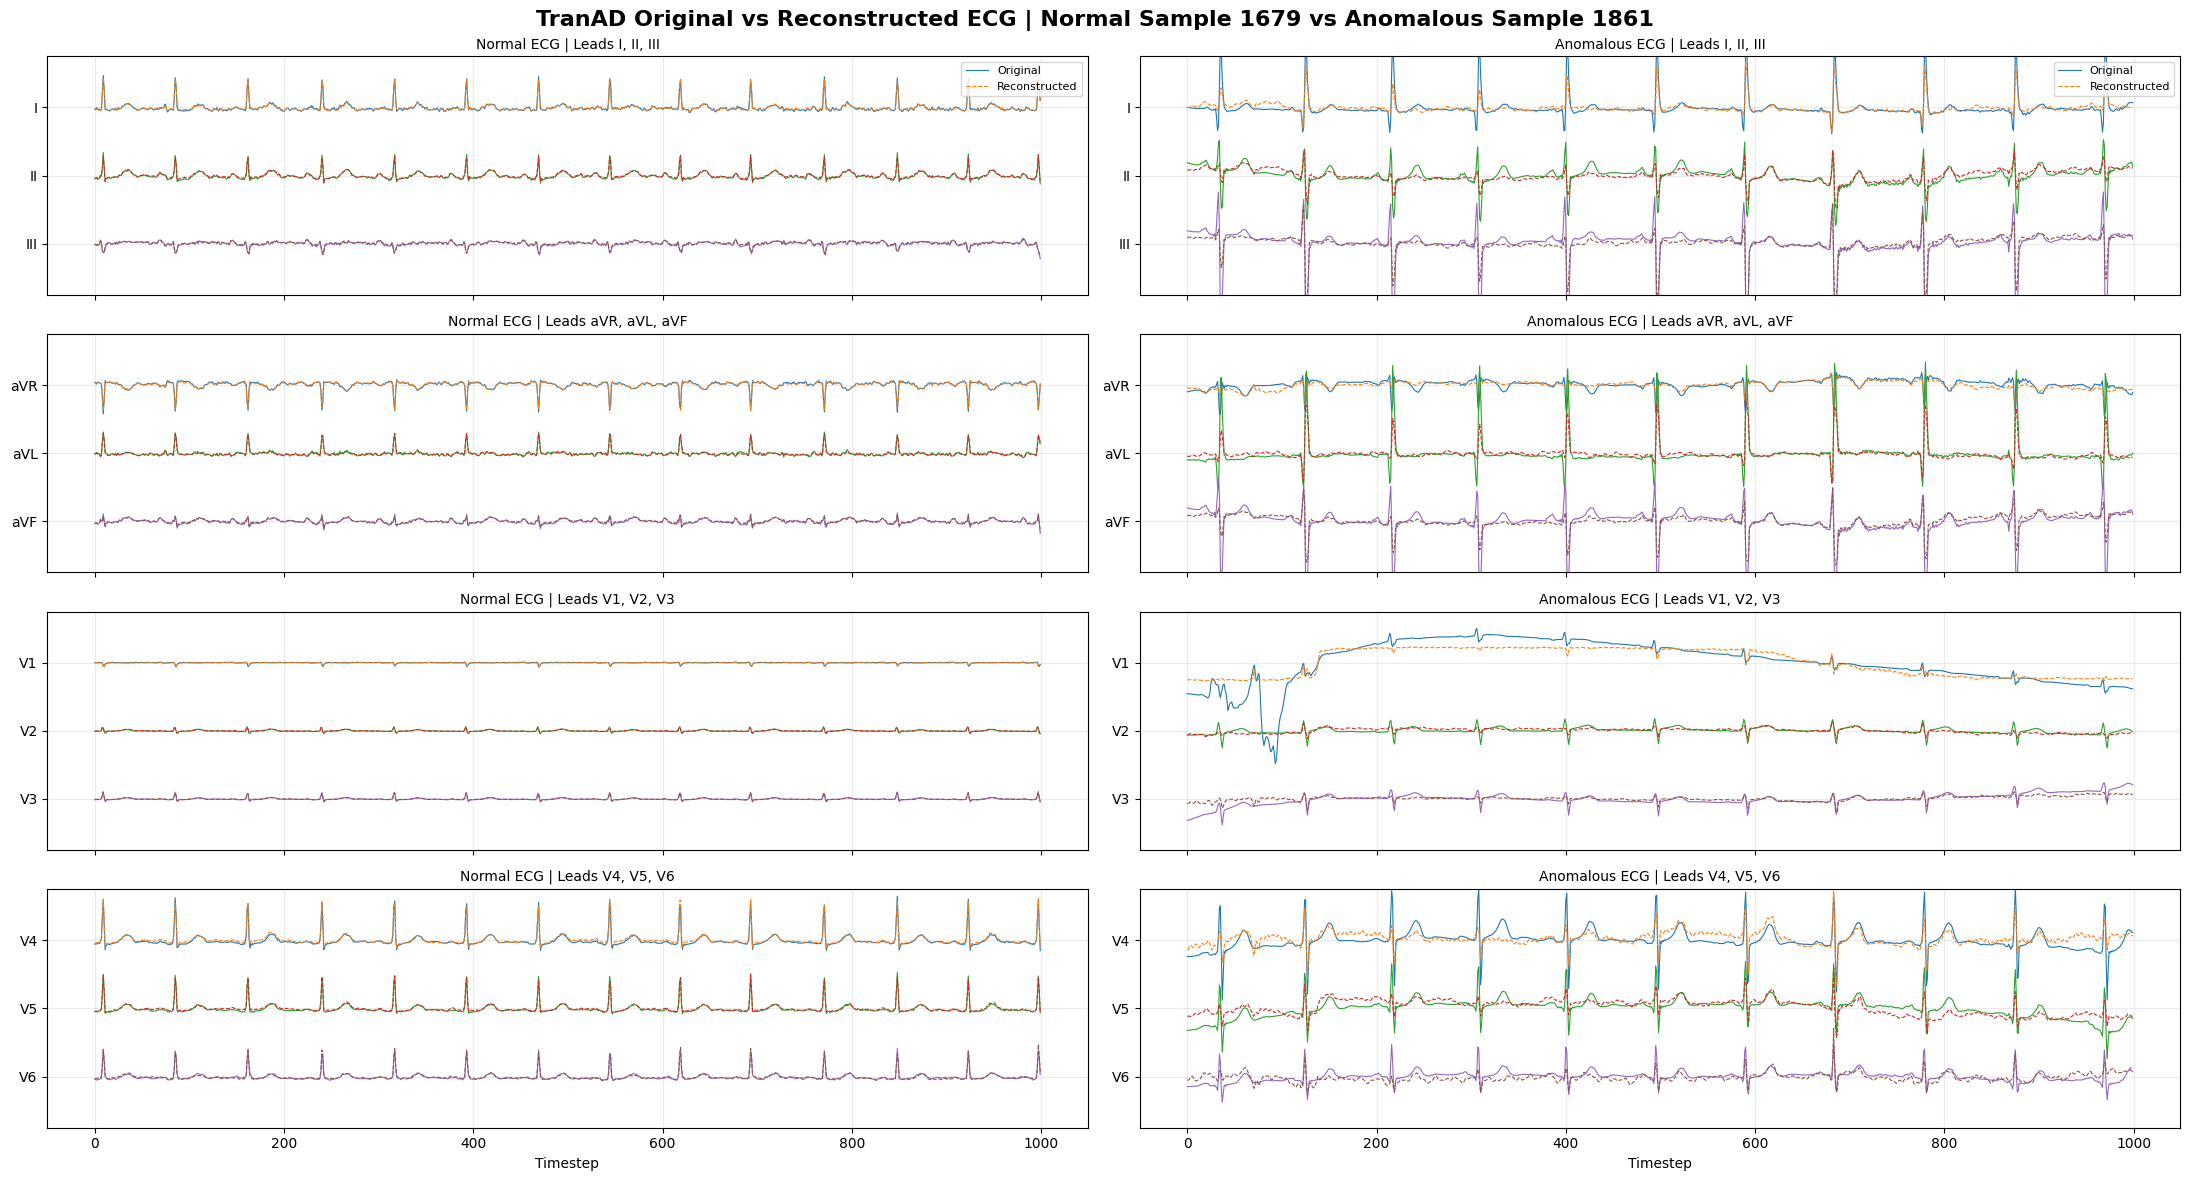

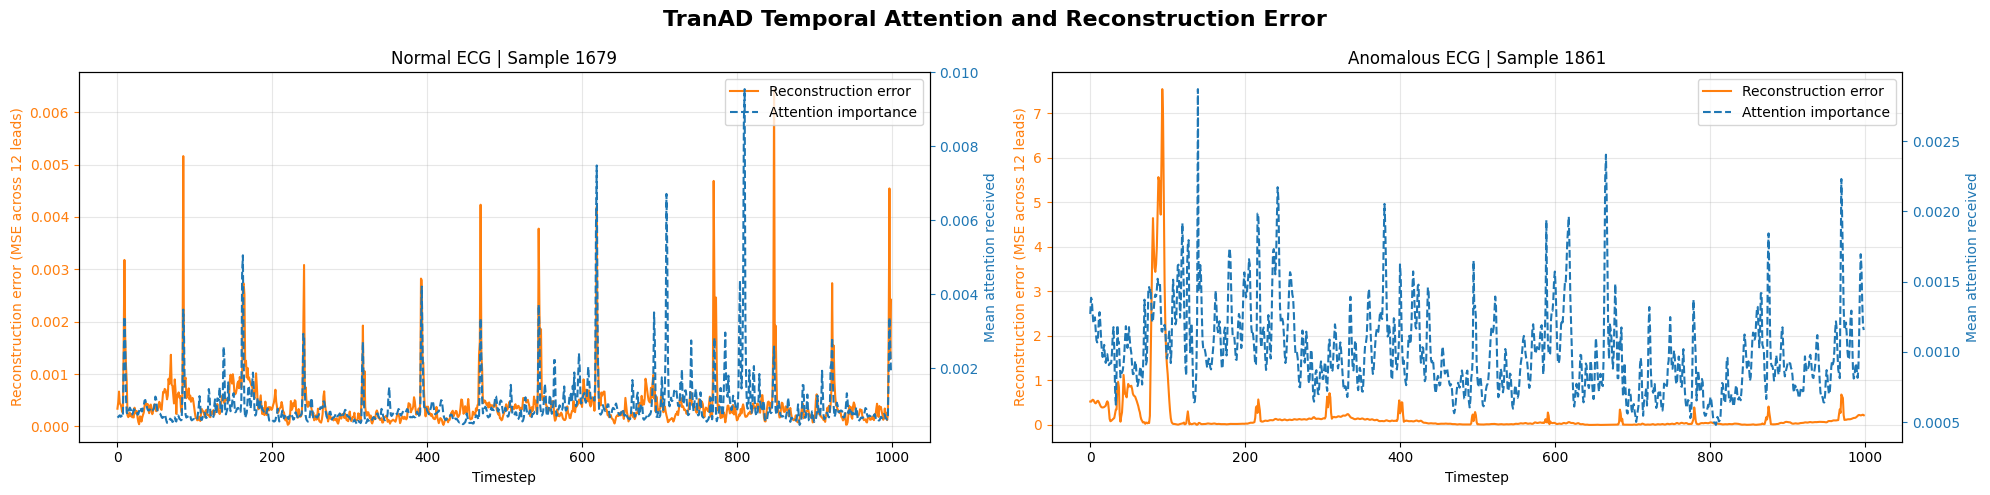

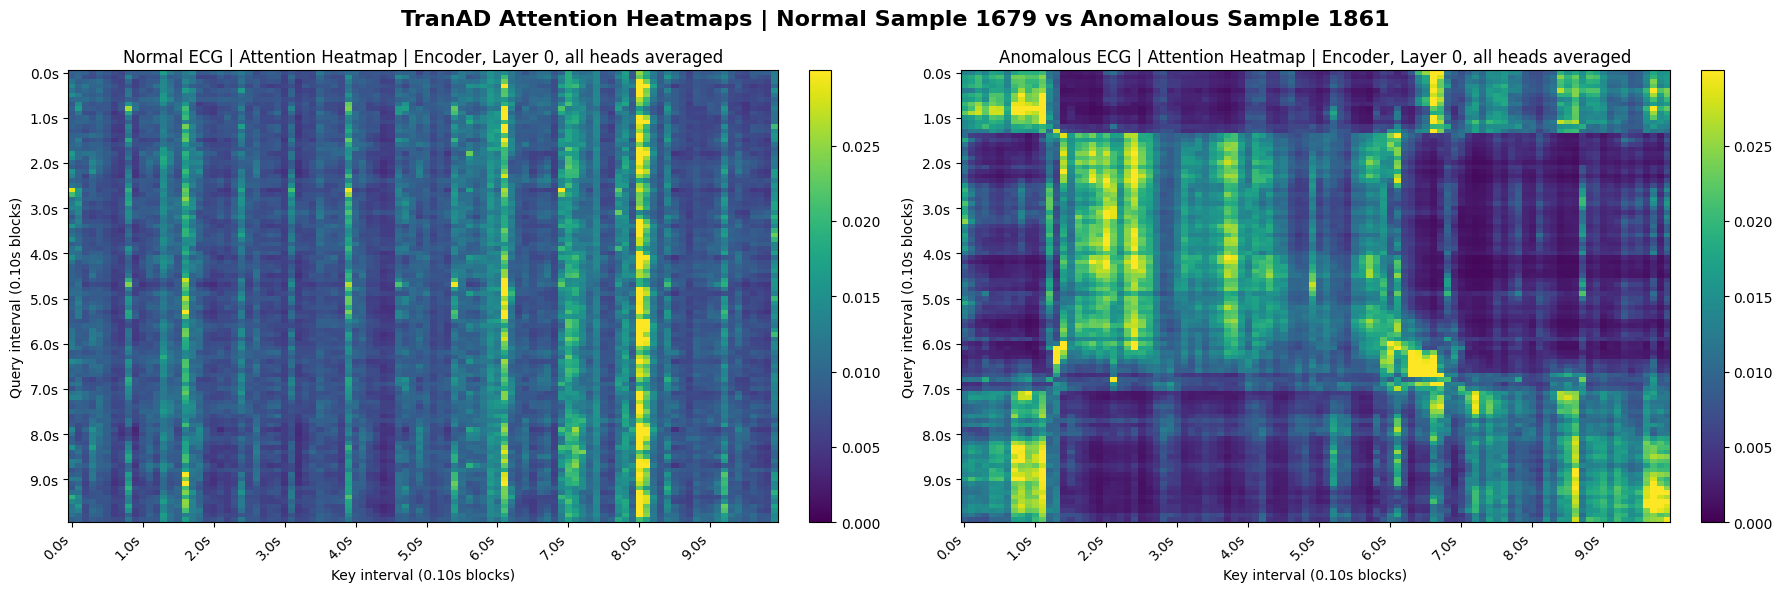

In [38]:
# TranAD Attention-based Explainability

import numpy as np

print("\n── TranAD Attention-based Explainability ─────────────────────")

Explainer = TranADExplainability(TranAD)

# Select meaningful samples, not arbitrary first samples
correct_normal = np.where(
    (y_test == 0) & (BinaryPredictions == 0)
)[0]

correct_anomaly = np.where(
    (y_test == 1) & (BinaryPredictions == 1)
)[0]

NormalIndex = correct_normal[
    np.argmin(AnomalyScores[correct_normal])
]

AnomalousIndex = correct_anomaly[
    np.argmax(AnomalyScores[correct_anomaly])
]

print("Selected normal index:", NormalIndex)
print("Normal score:", AnomalyScores[NormalIndex])

print("Selected anomalous index:", AnomalousIndex)
print("Anomalous score:", AnomalyScores[AnomalousIndex])

NormalECG, NormalLabel = test_dataset[NormalIndex]
AnomalousECG, AnomalousLabel = test_dataset[AnomalousIndex]

NormalECG = NormalECG.unsqueeze(0).to(TranAD.Device)
AnomalousECG = AnomalousECG.unsqueeze(0).to(TranAD.Device)

Explainer.CompareNormalAndAnomalousAttention(
    NormalWindow=NormalECG,
    AnomalousWindow=AnomalousECG,
    DatasetForInverseNorm=test_dataset,
    NormalIndex=NormalIndex,
    AnomalousIndex=AnomalousIndex,
    Component="Encoder",
    LayerIndex=0,
    HeadIndex=None,
    Percentile=99.0,
    UseIntervalHeatmap=True,
    BlockSize=10,
    Aggregation="mean_attention_mass",
    SamplingRate=100,
)

In [39]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score

for percentile in [50, 60, 70, 75, 80, 85, 90, 95]:
    threshold = np.percentile(AnomalyScores, percentile)
    preds = (AnomalyScores > threshold).astype(int)

    print("\nPercentile:", percentile)
    print("Threshold:", threshold)
    print("Predicted anomalies:", preds.sum())
    print(confusion_matrix(y_test, preds))
    print("Precision:", precision_score(y_test, preds, zero_division=0))
    print("Recall:", recall_score(y_test, preds, zero_division=0))
    print("F1:", f1_score(y_test, preds, zero_division=0))


Percentile: 50
Threshold: 0.03412415
Predicted anomalies: 1099
[[626 337]
 [473 762]]
Precision: 0.6933575978161965
Recall: 0.617004048582996
F1: 0.6529562982005142

Percentile: 60
Threshold: 0.042147063
Predicted anomalies: 879
[[726 237]
 [593 642]]
Precision: 0.7303754266211604
Recall: 0.5198380566801619
F1: 0.6073793755912961

Percentile: 70
Threshold: 0.055011965
Predicted anomalies: 660
[[811 152]
 [727 508]]
Precision: 0.7696969696969697
Recall: 0.41133603238866395
F1: 0.5361477572559367

Percentile: 75
Threshold: 0.06822434
Predicted anomalies: 550
[[849 114]
 [799 436]]
Precision: 0.7927272727272727
Recall: 0.35303643724696354
F1: 0.48851540616246497

Percentile: 80
Threshold: 0.086895846
Predicted anomalies: 440
[[880  83]
 [878 357]]
Precision: 0.8113636363636364
Recall: 0.2890688259109312
F1: 0.4262686567164179

Percentile: 85
Threshold: 0.11754695
Predicted anomalies: 330
[[908  55]
 [960 275]]
Precision: 0.8333333333333334
Recall: 0.22267206477732793
F1: 0.35143769968051

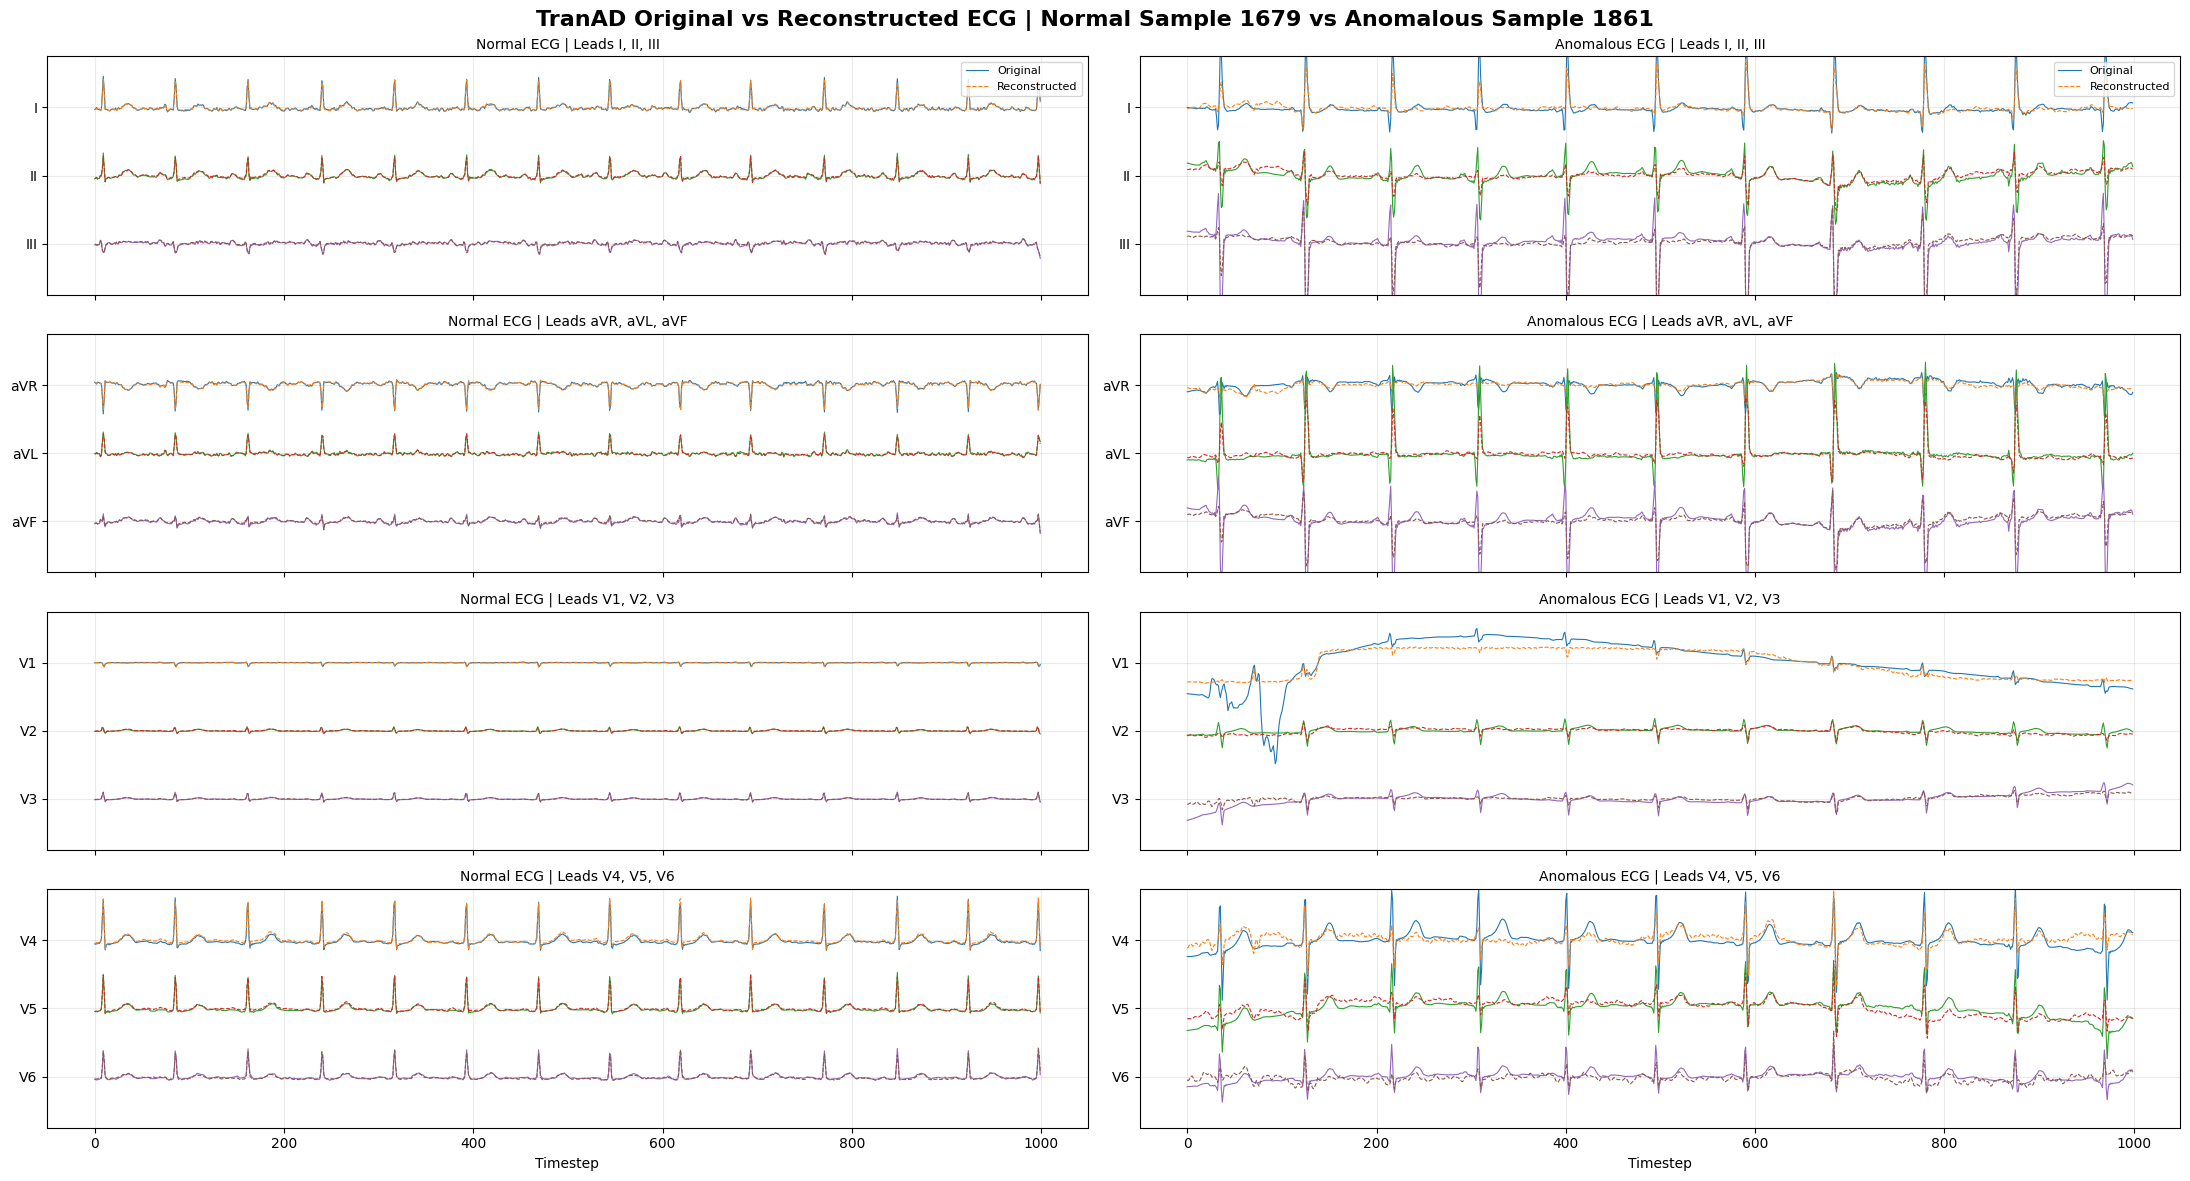

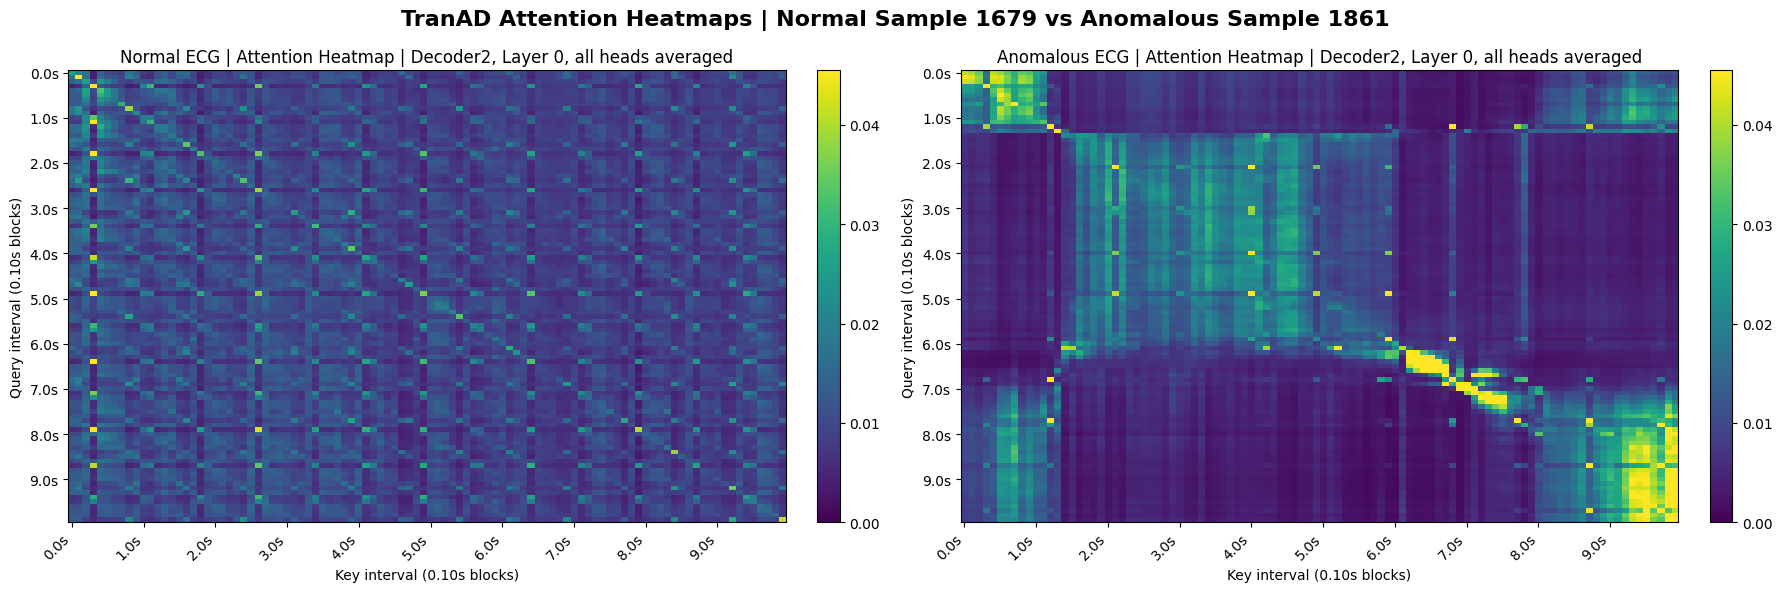

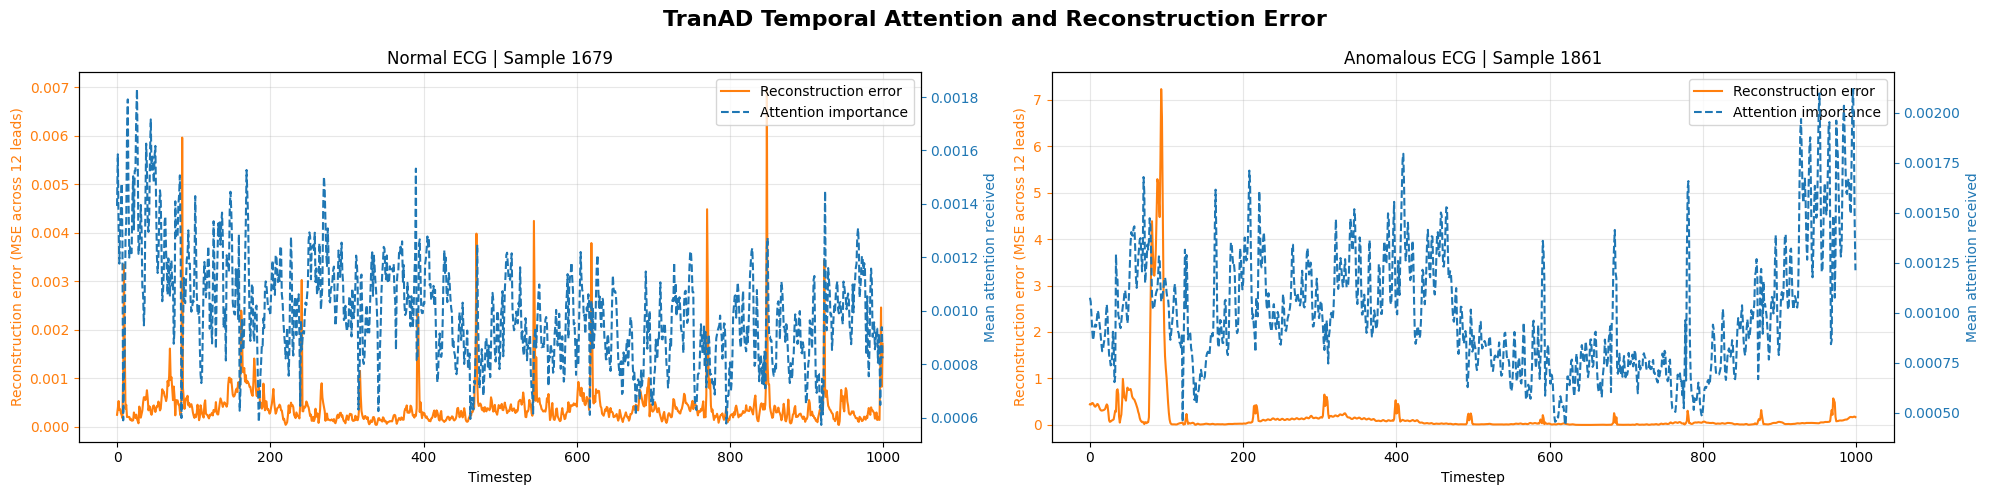

In [ ]:
# @title
Explainer.CompareNormalAndAnomalousAttention(
    NormalWindow=NormalECG,
    AnomalousWindow=AnomalousECG,
    DatasetForInverseNorm=test_dataset,
    NormalIndex=NormalIndex,
    AnomalousIndex=AnomalousIndex,
    Component="Decoder2",
    LayerIndex=0,
    HeadIndex=None,
    Percentile=99.0,
)

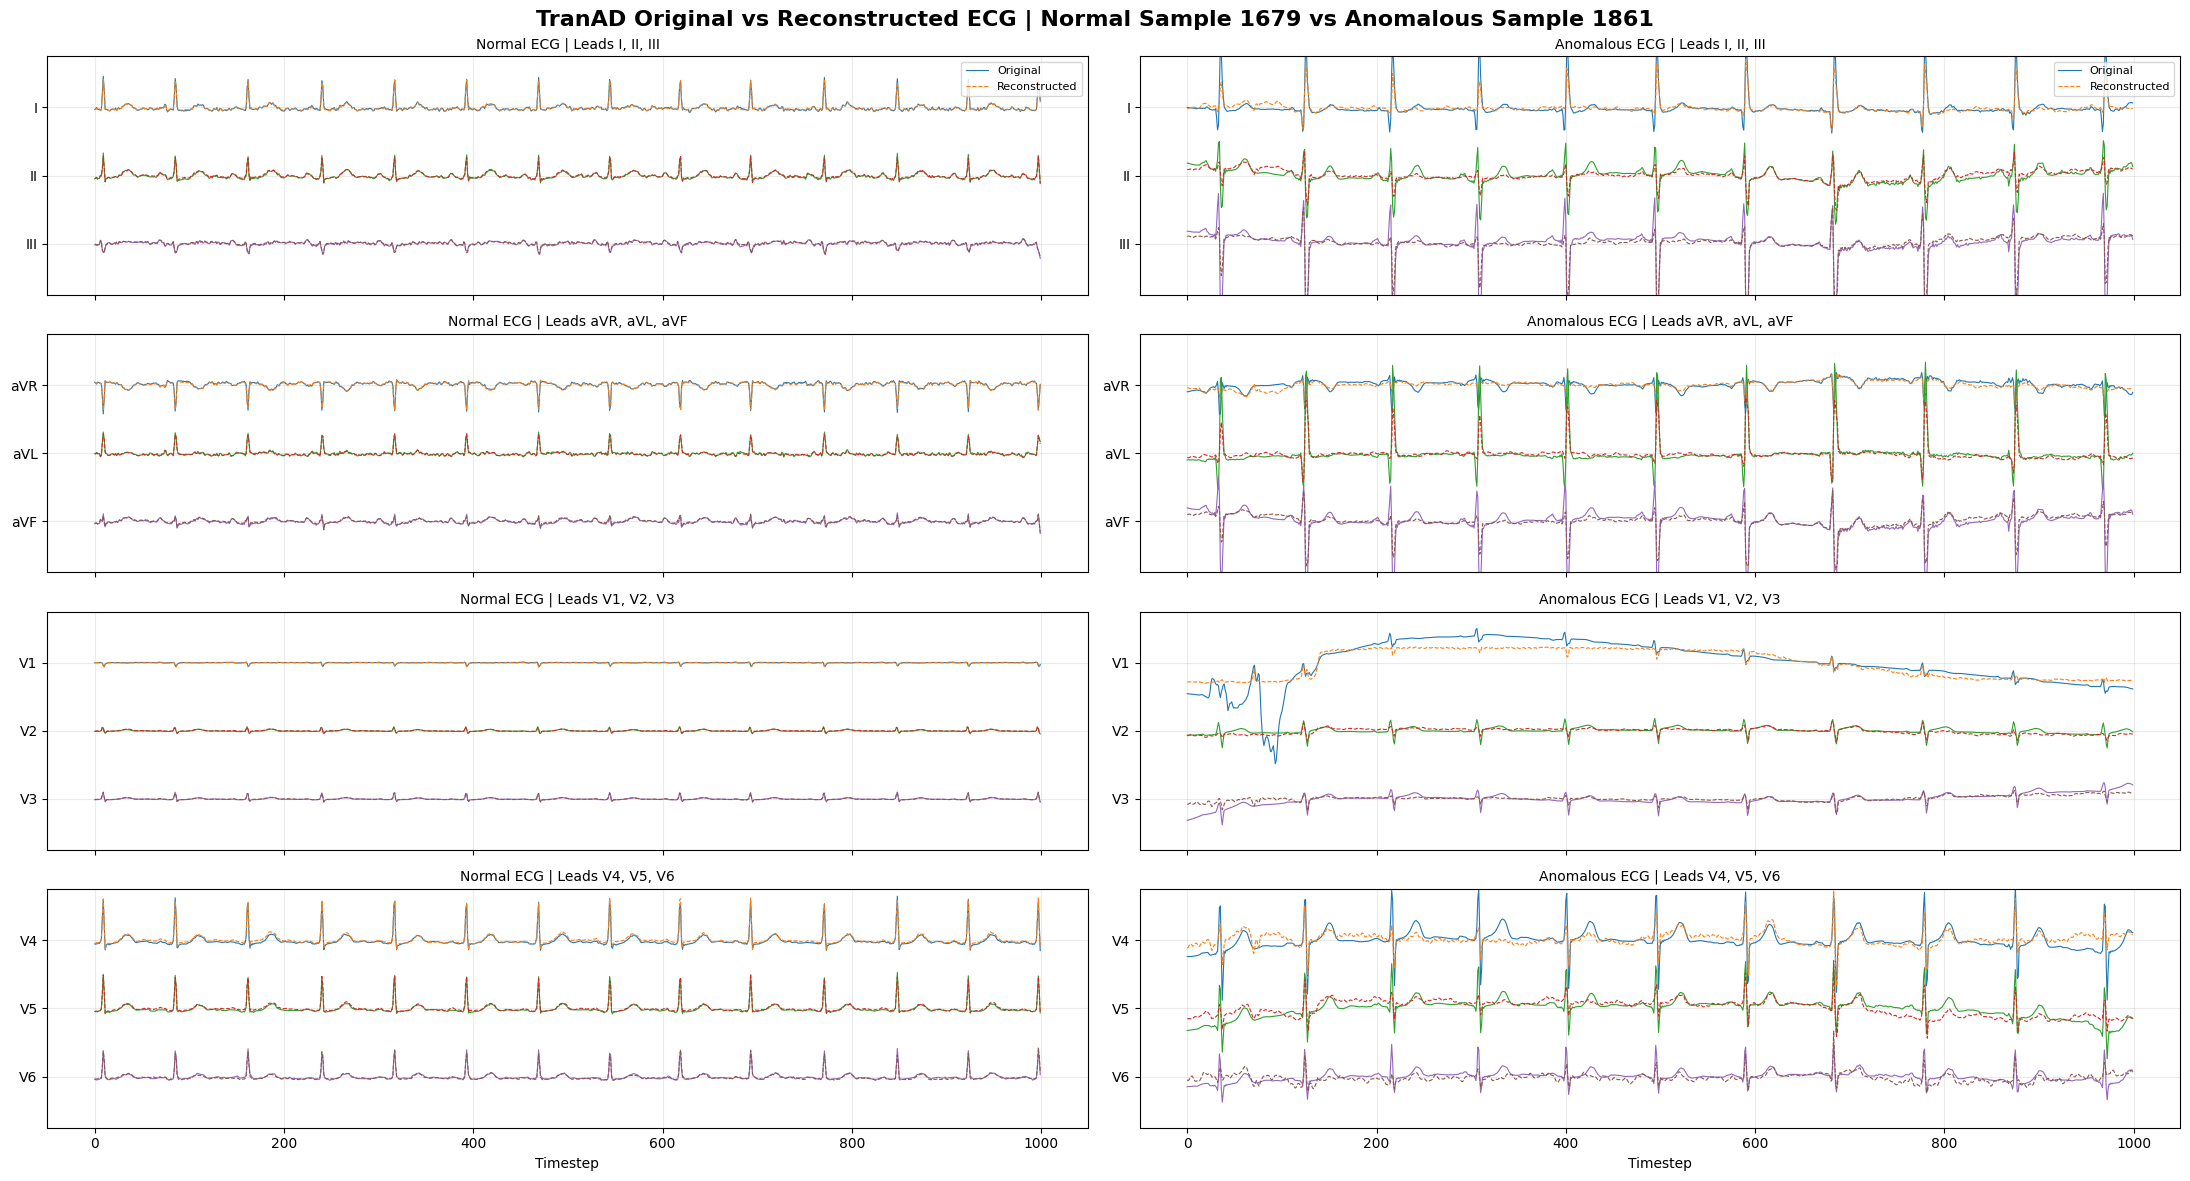

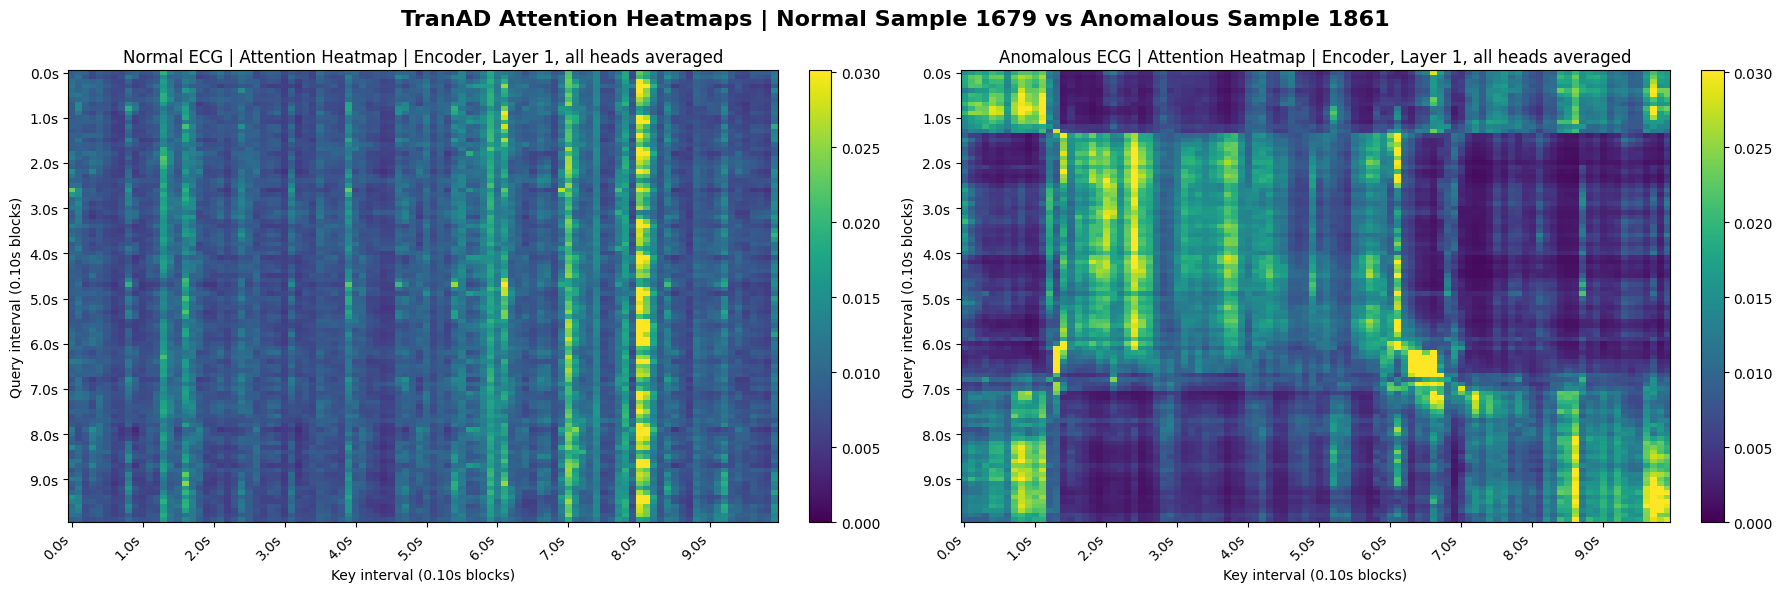

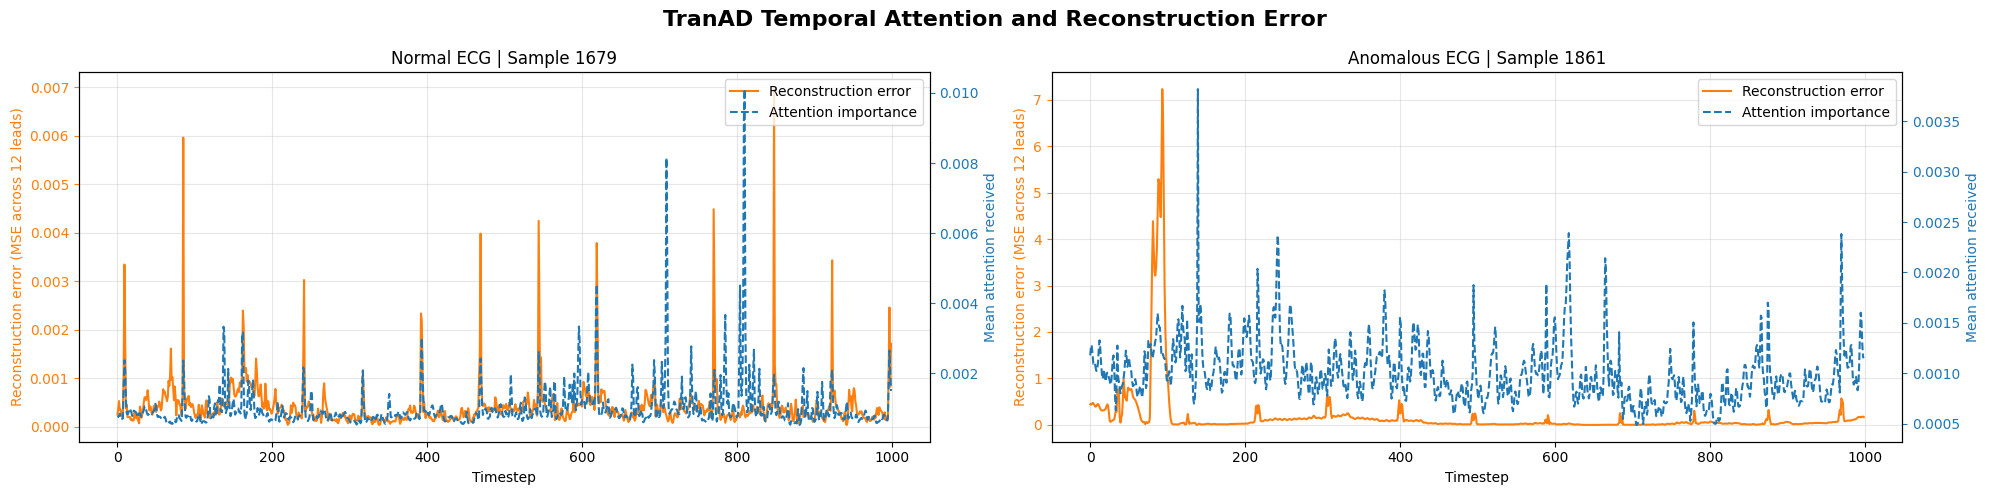

In [ ]:
# @title
Explainer.CompareNormalAndAnomalousAttention(
    NormalWindow=NormalECG,
    AnomalousWindow=AnomalousECG,
    DatasetForInverseNorm=test_dataset,
    NormalIndex=NormalIndex,
    AnomalousIndex=AnomalousIndex,
    Component="Encoder",
    LayerIndex=1,
    HeadIndex=None,
    Percentile=99.0,
)

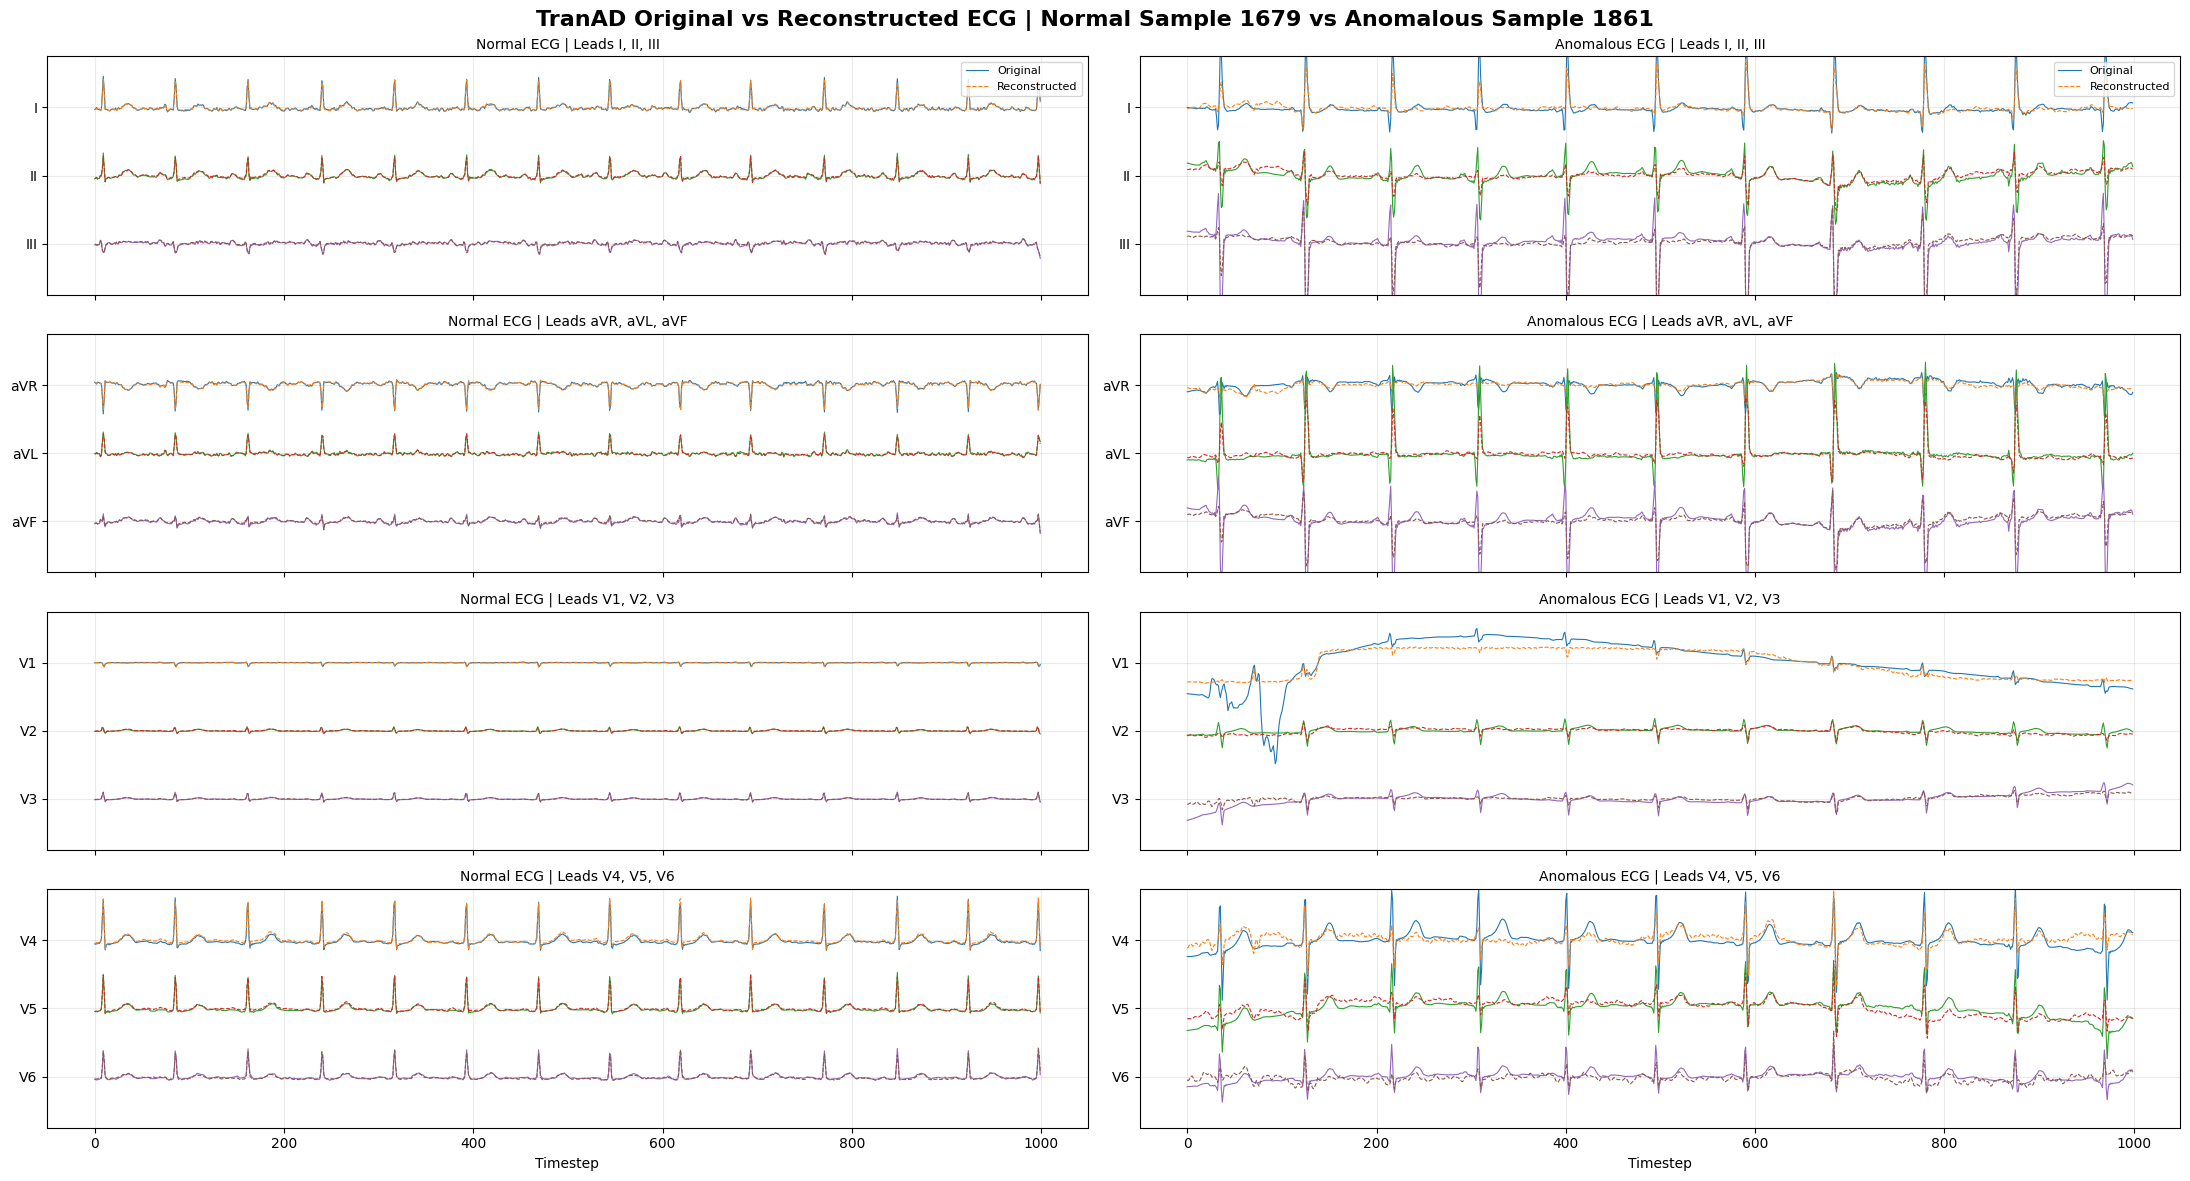

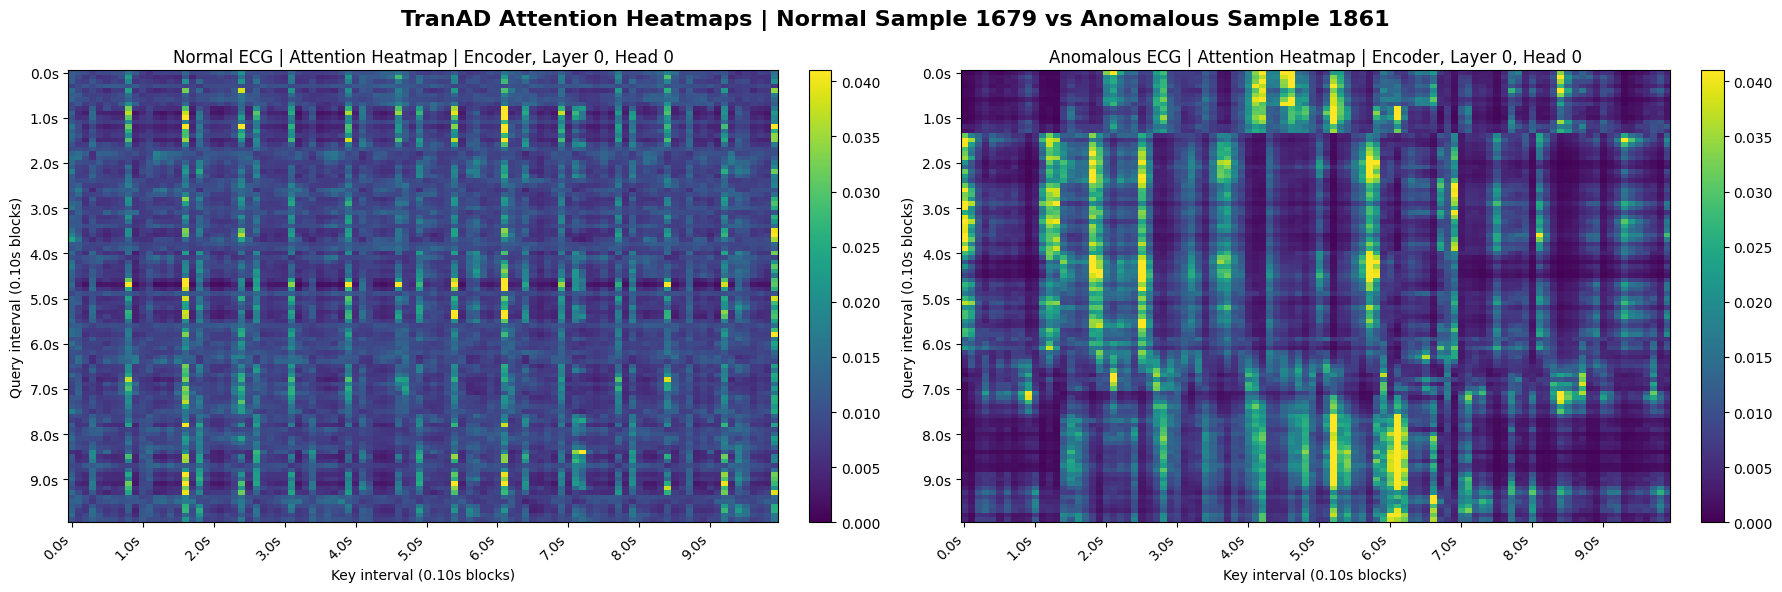

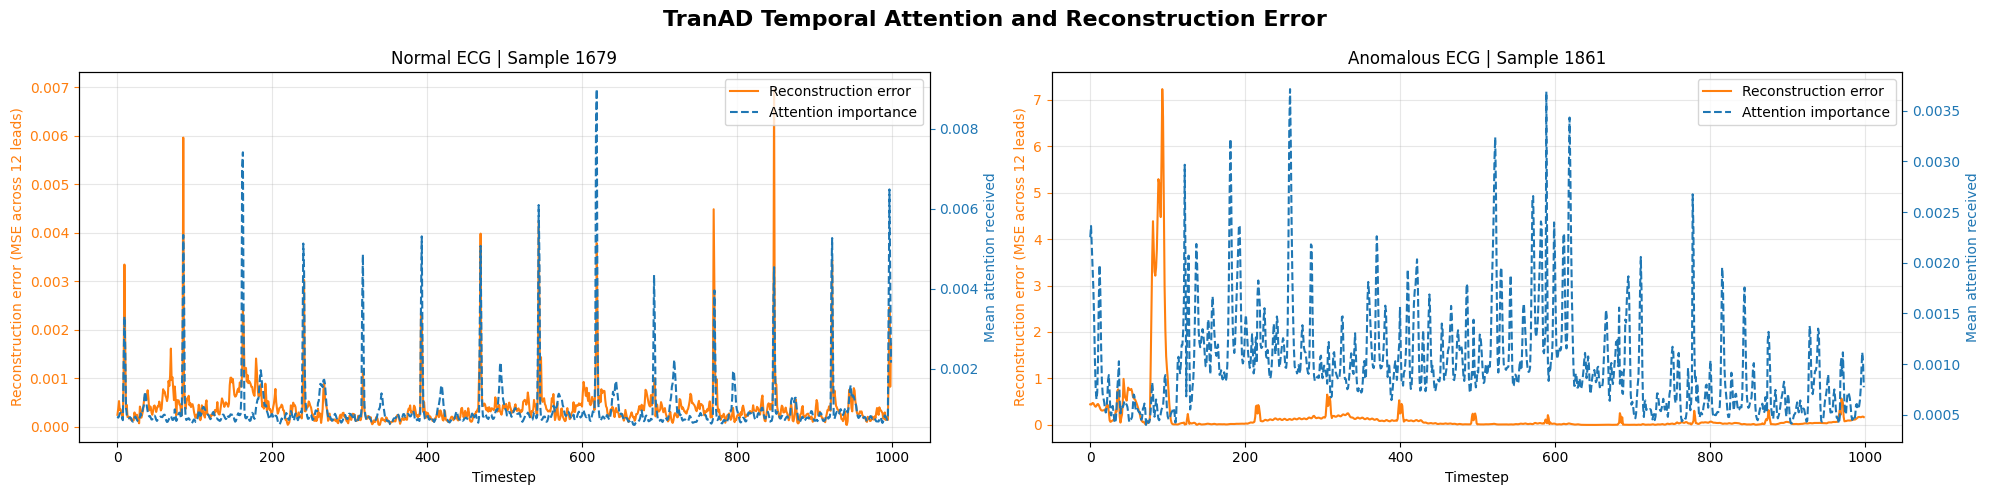

In [ ]:
# @title
Explainer.CompareNormalAndAnomalousAttention(
    NormalWindow=NormalECG,
    AnomalousWindow=AnomalousECG,
    DatasetForInverseNorm=test_dataset,
    NormalIndex=NormalIndex,
    AnomalousIndex=AnomalousIndex,
    Component="Encoder",
    LayerIndex=0,
    HeadIndex=0,
    Percentile=99.0,
)

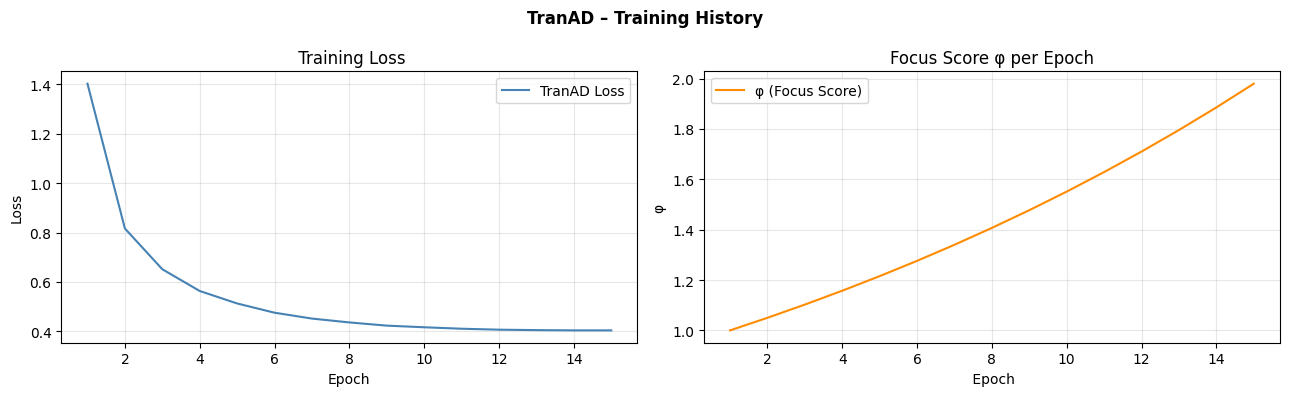

In [40]:
# Show training loss

Explainer.ShowTrainingHistory()